# Battery preprocessing and model diagnostics

This notebook explores saved outputs from Tasks 1–5. It reads data only: it does not
clean the workbooks, retrain models or modify results. First run the pipeline as described
in the project README, or use the saved outputs. Open this notebook from the repository
root or the `notebooks` folder.

**Interpretation:** the 2.5 Ah rating is provisional; relative EOL is based on cycle-2
high-current delivered capacity. Missing temperature, two cells and different current
protocols limit generalisation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "battery_thresholds.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "battery_thresholds.json").exists():
    raise FileNotFoundError("Open the notebook from the project root or notebooks folder")
sys.path.insert(0, str(ROOT / "scripts"))
from output_paths import TaskOutputs
OUT = TaskOutputs()
pd.set_option("display.max_columns", 20)

## 1. Cycle-level preprocessing and quality

The Gold table is built from phase-labelled Silver measurements. Capacity and energy
are integrated over valid intervals. `Computationally_Complete` describes the available
charge/discharge pair; it does **not** certify the physical test protocol. Review and
failure flags should be inspected, not interpreted automatically as cell faults.

In [2]:
gold = pd.read_csv(OUT / "03_gold_cycle_features/battery_cycle_features_gold.csv", dtype={"Dataset_ID": str})
quality = gold.groupby(["Dataset_ID", "Quality_Status"]).size().unstack(fill_value=0)
print("Cycle quality status:\n", quality.to_string())
print("\nTemperature availability:\n", gold.groupby("Dataset_ID")["Temperature_Status"].value_counts().to_string())
cols = ["Dataset_ID", "Cycle_Index", "Discharge_Capacity_Ah", "Coulombic_Efficiency_pct", "Mean_C_Rate_Charge", "Cycle_Duration_s", "Energy_Throughput_Wh", "Quality_Status"]
print("\nExample cycle features:\n", gold[cols].head(6).to_string(index=False))

Cycle quality status:
 Quality_Status  FAIL  REVIEW
Dataset_ID                  
001_2              2      99
002_4              2      99

Temperature availability:
 Dataset_ID  Temperature_Status
001_2       UNAVAILABLE           101
002_4       UNAVAILABLE           101

Example cycle features:
 Dataset_ID  Cycle_Index  Discharge_Capacity_Ah  Coulombic_Efficiency_pct  Mean_C_Rate_Charge  Cycle_Duration_s  Energy_Throughput_Wh Quality_Status
     001_2            1               2.269247                       NaN                 NaN            1736.0                   NaN           FAIL
     001_2            2               1.511447                100.523790            2.879180            2108.0             11.270650         REVIEW
     001_2            3               1.455527                 99.462238            2.878812            2061.0             10.903066         REVIEW
     001_2            4               1.419527                 99.430352            2.879314            2024

## 2. Check derived features and relative capacity

Coulombic efficiency is integrated discharge capacity divided by charge capacity.
Energy throughput combines charge and discharge energy. Capacity retention is relative
to the cycle-2 measured capacity, not verified nominal state of health. Values above
100% efficiency are retained as review candidates.

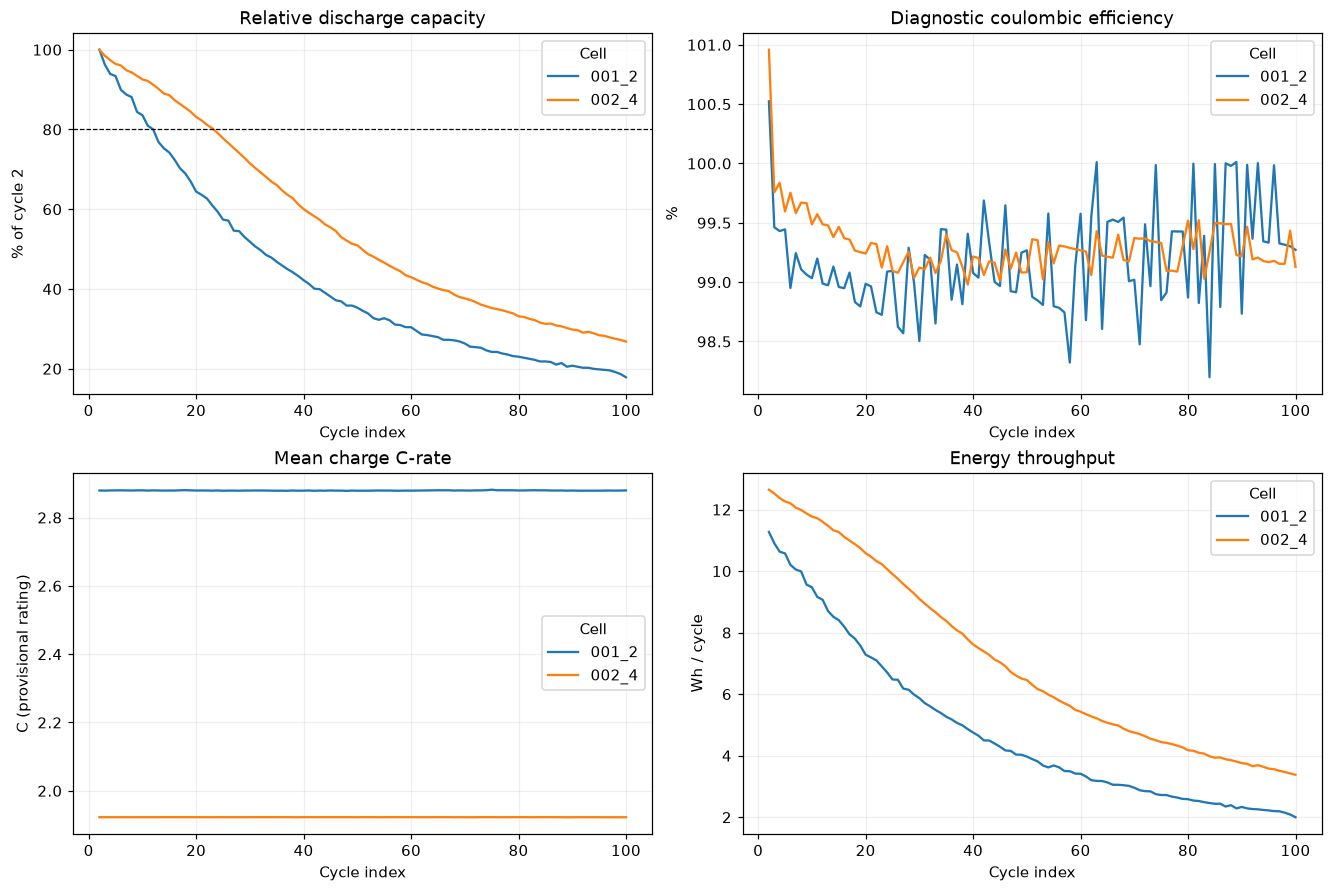

In [3]:
cycles = gold[gold.Computationally_Complete & gold.Discharge_Integration_Valid & gold.Cycle_Index.between(2, 100)].copy()
np.testing.assert_allclose(cycles.Coulombic_Efficiency_pct, 100 * cycles.Discharge_Capacity_Ah / cycles.Charge_Capacity_Ah, rtol=1e-6)
np.testing.assert_allclose(cycles.Energy_Throughput_Wh, cycles.Charge_Energy_Wh + cycles.Discharge_Energy_Wh, rtol=1e-6)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for cell, g in cycles.groupby("Dataset_ID"):
    g = g.sort_values("Cycle_Index")
    axes[0, 0].plot(g.Cycle_Index, 100 * g.Discharge_Capacity_Ah / g.Discharge_Capacity_Ah.iloc[0], label=cell)
    axes[0, 1].plot(g.Cycle_Index, g.Coulombic_Efficiency_pct, label=cell)
    axes[1, 0].plot(g.Cycle_Index, g.Mean_C_Rate_Charge, label=cell)
    axes[1, 1].plot(g.Cycle_Index, g.Energy_Throughput_Wh, label=cell)
axes[0, 0].axhline(80, color="black", ls="--", lw=0.8)
for ax, title, ylabel in zip(axes.flat, ["Relative discharge capacity", "Diagnostic coulombic efficiency", "Mean charge C-rate", "Energy throughput"], ["% of cycle 2", "%", "C (provisional rating)", "Wh / cycle"]):
    ax.set(title=title, xlabel="Cycle index", ylabel=ylabel); ax.grid(alpha=.2); ax.legend(title="Cell")
plt.show()

## 3. Relative EOL and the nominal-capacity limitation

The observed relative EOL is the first complete, valid discharge cycle below 80% of
its own cycle-2 value. Because the provisional nominal rating is unverified and both
first complete measurements are below 80% of that rating, a nominal-threshold crossing
cannot be dated from these complete observations.

In [4]:
rows = []
for cell, g in cycles.groupby("Dataset_ID"):
    g = g.sort_values("Cycle_Index")
    q2 = float(g.loc[g.Cycle_Index.eq(2), "Discharge_Capacity_Ah"].iloc[0])
    crossing = g.loc[g.Discharge_Capacity_Ah.lt(.8 * q2), "Cycle_Index"]
    rows.append({"Cell": cell, "Cycle-2 Ah": q2, "Relative threshold Ah": .8*q2, "Observed relative EOL cycle": int(crossing.iloc[0]) if len(crossing) else None})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 Cell  Cycle-2 Ah  Relative threshold Ah  Observed relative EOL cycle
001_2      1.5114                 1.2092                           13
002_4      1.6878                 1.3502                           24


## 4. Chronological model comparison

The saved comparison evaluates fixed-origin 15-cycle capacity forecasts after cycle 85.
The LSTM and Random Forest predict recursively; their errors can accumulate. The
physics-constrained model is a phenomenological surrogate, not identification of a
specific degradation mechanism. These results evaluate the same two cells used for
training history, not unseen-cell generalisation.

Dataset_ID                         Model  MAE_Ah  RMSE_Ah       R2
     001_2                 Random Forest  0.0108   0.0125   0.2946
     001_2                   Persistence  0.0265   0.0303  -3.1872
     001_2                          LSTM  0.0332   0.0380  -5.5568
     001_2 Physics-constrained surrogate  0.0518   0.0522 -11.4023
     001_2                   Exponential  0.0754   0.0758 -25.1162
     002_4                 Random Forest  0.0197   0.0214   0.0897
     002_4 Physics-constrained surrogate  0.0263   0.0274  -0.4898
     002_4                   Exponential  0.0263   0.0274  -0.4898
     002_4                   Persistence  0.0373   0.0434  -2.7417
     002_4                          LSTM  0.0456   0.0512  -4.2022


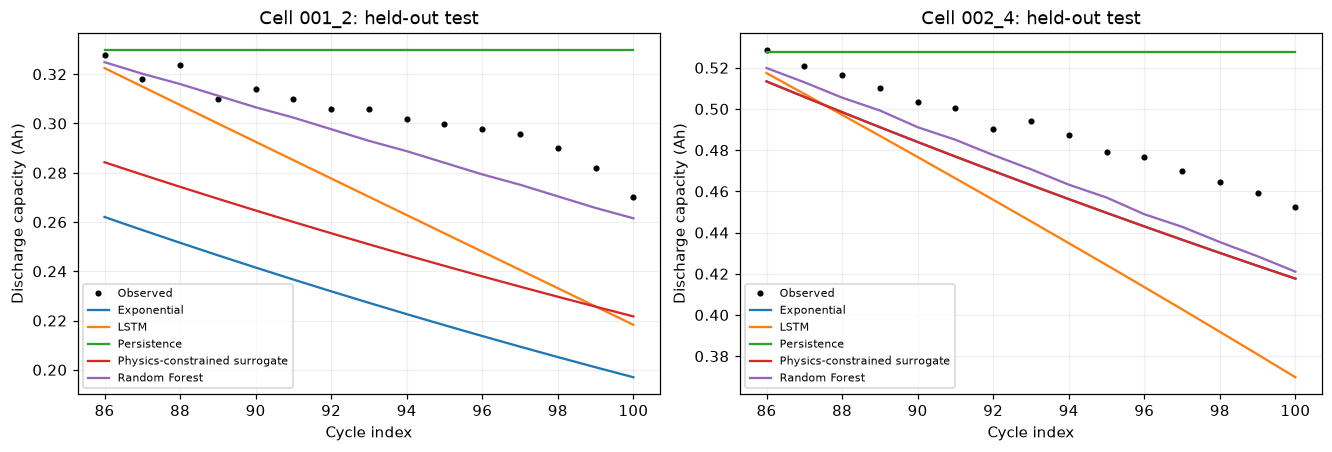

In [5]:
scores = pd.read_csv(OUT / "05_capacity_model_comparison/metrics.csv", dtype={"Dataset_ID": str})
pred = pd.read_csv(OUT / "05_capacity_model_comparison/predictions.csv", dtype={"Dataset_ID": str})
test_scores = scores[scores.Stage.eq("test")].sort_values(["Dataset_ID", "RMSE_Ah"])
print(test_scores[["Dataset_ID", "Model", "MAE_Ah", "RMSE_Ah", "R2"]].round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (cell, g) in zip(axes, pred[pred.Stage.eq("test")].groupby("Dataset_ID")):
    actual = g[g.Model.eq("Persistence")].sort_values("Cycle_Index")
    ax.plot(actual.Cycle_Index, actual.Observed_Ah, "ko", ms=3, label="Observed")
    for model, h in g.groupby("Model"):
        h = h.sort_values("Cycle_Index"); ax.plot(h.Cycle_Index, h.Predicted_Ah, label=model)
    ax.set(title=f"Cell {cell}: held-out test", xlabel="Cycle index", ylabel="Discharge capacity (Ah)"); ax.grid(alpha=.2); ax.legend(fontsize=7)
plt.show()

## 5. RUL comparison and forecast coverage

Errors are calculated only for attempts with a crossing within the horizon. Coverage
and attempt counts must accompany MAE; multiple LSTM seeds are repeated model runs,
not independent cells.

In [6]:
rul = pd.read_csv(OUT / "11_rul_model_comparison/all_method_common_metrics.csv", dtype={"Dataset_ID": str})
print(rul[["Dataset_ID", "Method", "Attempts", "Scored", "Coverage_pct", "MAE_Cycles"]].round(2).to_string(index=False))

Dataset_ID                               Method  Attempts  Scored  Coverage_pct  MAE_Cycles
     001_2       Exponential (individual curve)         2       2         100.0        0.50
     001_2            Linear (individual curve)         2       2         100.0        1.00
     001_2              Minimal LSTM (window 1)         6       6         100.0        1.33
     001_2              Minimal LSTM (window 3)         6       6         100.0        3.67
     001_2         Power law (individual curve)         2       2         100.0        1.00
     001_2                       Shared XGBoost         2       2         100.0        2.50
     001_2 Square-root cycle (individual curve)         2       2         100.0        4.50
     002_4       Exponential (individual curve)         2       2         100.0        2.00
     002_4            Linear (individual curve)         2       2         100.0        0.50
     002_4              Minimal LSTM (window 1)         6       6         100.0 

## 6. Differential voltage and pack scaling

Task 2 stores candidate dV/dQ minima and sensitivity checks. Candidates have not been
matched to electrode features across cycles, so the results do not quantify LLI or LAM.
Task 5 is a synthetic capacity-envelope scenario: temperature, cell variation and
balancing parameters are assumed, and its 80% threshold uses an ideal identical-cell
reference rather than each simulated pack's own starting capacity.

In [7]:
dvdq = pd.read_csv(OUT / "06_differential_voltage/feature_cycle_summary.csv", dtype={"cell": str})
pack = pd.read_csv(OUT / "13_pack_scaling/scenario_summary.csv", dtype={"Dataset_ID": str})
print("dV/dQ candidate counts by cell and cycle:\n", dvdq[["cell", "cycle", "candidate_count", "stable_count"]].to_string(index=False))
print("\nIllustrative pack scenarios:\n", pack.round(3).to_string(index=False))

dV/dQ candidate counts by cell and cycle:
  cell  cycle  candidate_count  stable_count
001_2      2                0             0
001_2     10                0             0
001_2     25                5             0
001_2     50                8             7
001_2     75               10             6
001_2    100               10             7
002_4      2                0             0
002_4     10                0             0
002_4     25                1             0
002_4     50                5             0
002_4     75                6             1
002_4    100                9             2

Illustrative pack scenarios:
 Dataset_ID            Scenario  Mean_EOL  Min_EOL  Max_EOL  Mean_Initial_Balance_Loss_Wh
     001_2     gradient_active      8.96      7.0     10.0                         0.066
     001_2 gradient_no_balance      8.97      7.0     10.0                         0.000
     001_2    gradient_passive      8.59      7.0     10.0                         1.56

For the required capacity, efficiency, anomaly and RUL figures, see
[visualization_report.ipynb](visualization_report.ipynb). For methods and limitations,
see the task READMEs and the five-page technical report.